In [ ]:
import xarray as xr

## GraphExploration

Visualize the effect of setting `edge_weight_scale`. This is kept in the repository for reference only.

In [ ]:
from matplotlib import pyplot as plt
import numpy as np

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
from torch_geometric.data import Dataset as GDataset
from torch_geometric.data import Data as GData
from torch_geometric.loader import DataLoader as GDataLoader
import torch

import networkx as nx
import torch_geometric

/work/ka1176/caroline/gitlab/wind-wave-model-emulator/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
import sys
sys.path.append("..")

from src.data.WWMDatasets import GraphWWMDataset, SimpleWWMDataset

In [ ]:
import seaborn as sns

In [ ]:
ds = GraphWWMDataset(data_dir="/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_RUN04b_JUWELS_wpile.zarr/", 
                          data_range=[1, 3], 
                          features=["windSpeedX", "windSpeedY"], 
                          targets=["sigWaveHeight"], 
                          graph_features=["SCHISM_hgrid_edge_nodes"],
                          node_idx_csv="../src/data/node_selection/node_idx_closest_center_10000.csv",
                          max_nodes=500,
                          edge_weight_scale=2000.,
                         )

In [ ]:
len(ds)

180340

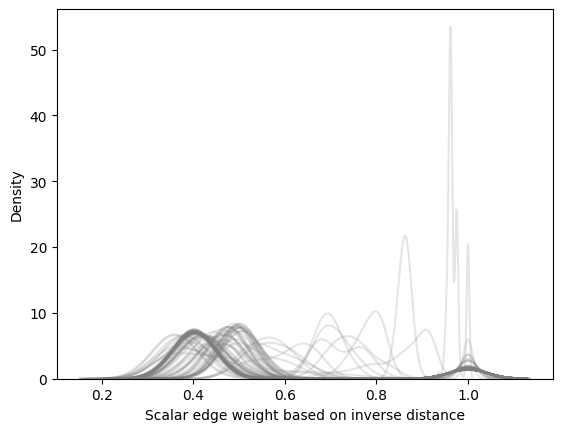

In [ ]:
for i in range(0, 2500, 25):
    graph = ds.get(i)
    #plt.hist(graph.edge_weight, bins=np.arange(0, 1.1, 0.1), alpha=0.2);
    sns.kdeplot(graph.edge_weight, color="C7", alpha=0.2);

plt.xlabel("Scalar edge weight based on inverse distance");

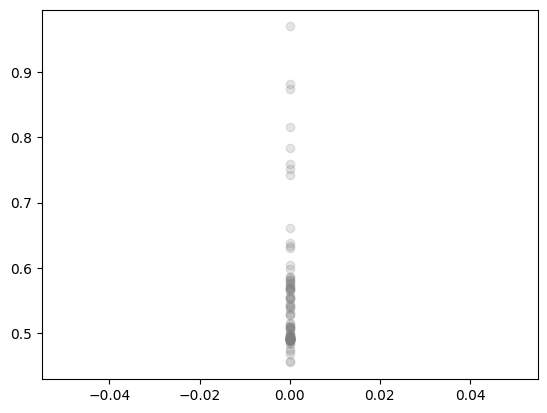

In [ ]:
for i in range(0, 2500, 25):
    graph = ds.get(i)
    #plt.hist(graph.edge_weight, bins=np.arange(0, 1.1, 0.1), alpha=0.2);
    plt.scatter(0, graph.edge_weight.mean(), color="C7", alpha=0.2);

#plt.xlabel("Scalar edge weight based on inverse distance");

In [ ]:
m = []
for i in range(2520):
    graph = ds.get(i)
    m.append(graph.edge_weight.mean())

In [ ]:
graph

WWMGraphData(x=[500, 2], edge_index=[2, 3304], y=[500, 1], edge_weight=[3304], center_idx=341)

In [ ]:
from torch_geometric.utils import scatter

for i in range(0, 2520, 500):
    graph

edge_index = graph.edge_index
edge_weight = graph.edge_weight
src = edge_index[0]                      # node whose neighbourhood we describe
n = int(edge_index.max()) + 1            # or data.num_nodes

deg   = scatter(torch.ones_like(edge_weight), src, dim_size=n, reduce="sum")
mean  = scatter(edge_weight,      src, dim_size=n, reduce="mean")
mean2 = scatter(edge_weight**2,   src, dim_size=n, reduce="mean")
std   = (mean2 - mean**2).clamp_min(0).sqrt()

wmin  = scatter(edge_weight, src, dim_size=n, reduce="min")
wmax  = scatter(edge_weight, src, dim_size=n, reduce="max")

cv    = std / mean.clamp_min(1e-12)      # relative spread, comparable across nodes
rng   = wmax - wmin

<Axes: ylabel='Density'>

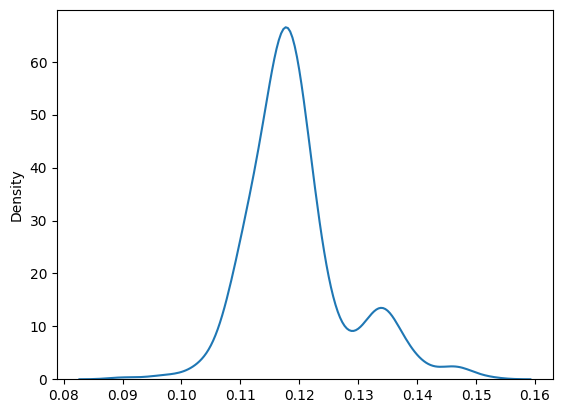

In [ ]:
sns.kdeplot(std)

Text(0.5, 0, 'Mean edge weight across subgraph')

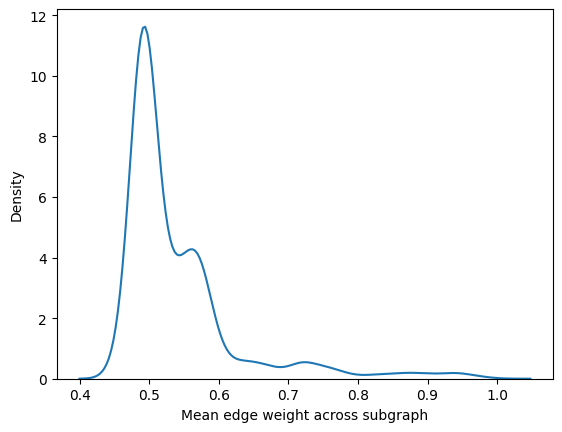

In [ ]:
sns.kdeplot(np.asarray(m))
plt.xlabel("Mean edge weight across subgraph")